# 1D Lagrangian turbulence, B + Scat4: $D_k = D_{KL}(p\|q_k)$ per group of potentials

$p \propto \exp(-\sum_j \theta_j^T\phi_j)$, $A_k = \theta_k^T\phi_k$, $q_k \propto p\,e^{A_k}$;
$D_k = \log E_p[e^{A_k - E_p A_k}] \ge 0$ (nats). Code sign: $\log p = +\Theta\cdot\phi$, so $A_k = -C_k$.
Groups: summed energy of the group (never a sum of single $D_k$). $L_6$ is never removed.

**Assumptions** (flagged): $E_p$ is estimated on the GENERATED signals (law $\rho_1$ of the SDE endpoint) while
$\theta = \Theta_{reg}(t=1)$; $\hat D_k$ is exact only if $\rho_1 = p_{\Theta_{reg}}$. Error bar = max(std over seeds, bootstrap std).

**What the numbers mean:** $\hat D_k \le D_k$ (Jensen: $E\log\bar W \le \log E\bar W$, on average) and $I_k \le D_k$, with
$I_k = D_{KL}(p\|q_k^*)$ the information of term $k$ (other $\theta$ refitted). $\hat D_k$ and $I_k$ are not ordered.
Groups with degenerate weights (fewer than 100 signals effectively share the weight, ESS < 100, or $\hat D_k$ still rising with N, in any seed) are shown as
LOWER BOUNDS $D_k \ge \hat D_k$ (open circles / "$\ge$"), no error bar: "removing this term alone, without
refit, changes p strongly", NOT "this term carries much information". Gaussian rule: $N \gg e^{\mathrm{Var}(A)/2} = e^{D_{KL}(q_k\|p)}$
samples needed (column log10_N_needed). $\frac12\mathrm{Var}(A_k)$ is the 2nd-cumulant approximation only.
Heavy computation: `kl_groups/launch_kl_groups.sh` (cache_energies.py + compute_H.py); this notebook only reads
`results/<TAG>/H_lagrangian.csv`.

In [1]:
import os, sys
from pathlib import Path
TAG = 'run1'          # results/<TAG>
os.environ['KL_RESULTS'] = str(Path('results') / TAG)
sys.path.insert(0, '.')
import plots as P
import matplotlib.pyplot as plt
%matplotlib inline
DS = 'lagrangian'
df, agg = P.load(DS, Path(os.environ['KL_RESULTS']))
print(df.seed.unique(), 'seeds |', df.N.iloc[0], 'samples per seed')

[900 901 902 903 904] seeds | 10000 samples per seed


## $D_k$ per group, one marker per seed, with $\frac12$Var alongside

### $D_k$ per group, one marker per seed (nats, log scale)
- **o** D̂_k = log (1/N) Σ_i e^{a_i − ā}, a_i = A_k on the generated signals. Open circle = lower bound (D_k ≥ D̂_k):
  in that seed a few signals carry almost all the weight e^{a_i}, so the estimate misses the tail. Filled = measured.
- **x** ½Var(A_k): leading (2nd-cumulant) term of D_k; exact if A_k is Gaussian.
- **–** Gaussian floor σ√(2 ln N) − ln N: the value of D̂_k when one sample dominates, for Gaussian A_k (not drawn if < 0).
- **◆** mean ± std over seeds of D̂_k (for open circles: spread of the bounds, not an error bar on D_k).

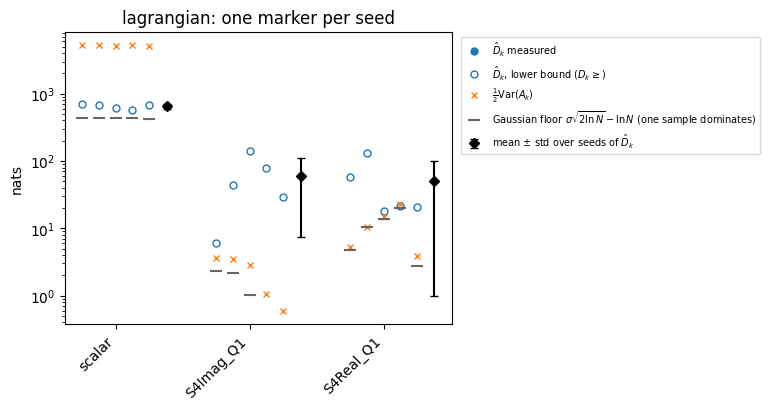

In [2]:
P.bars(agg, title=DS); plt.show()

## $D_k$ per single potential, sorted

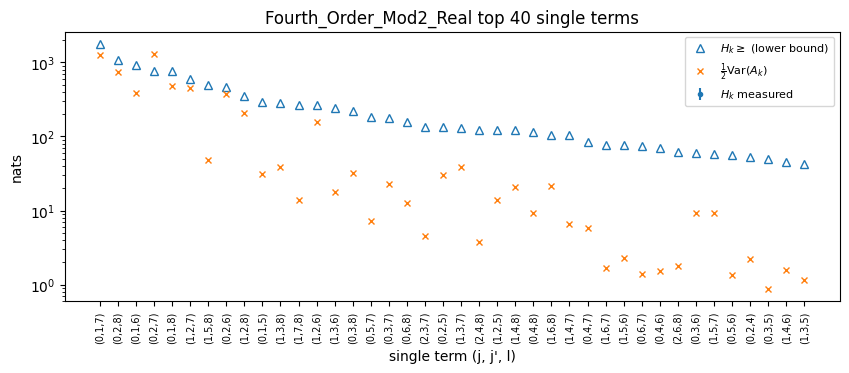

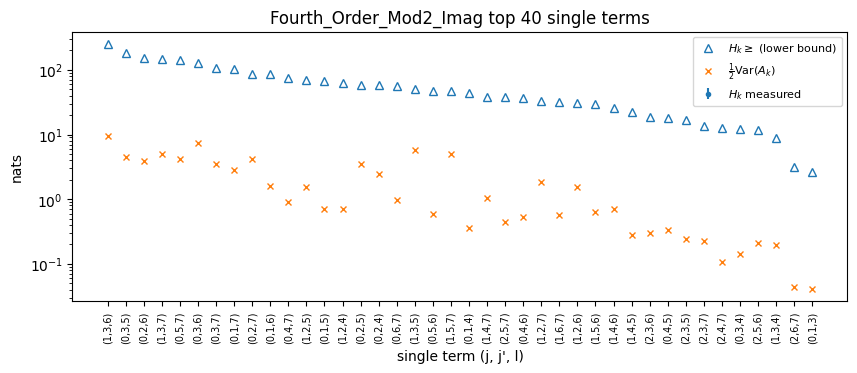

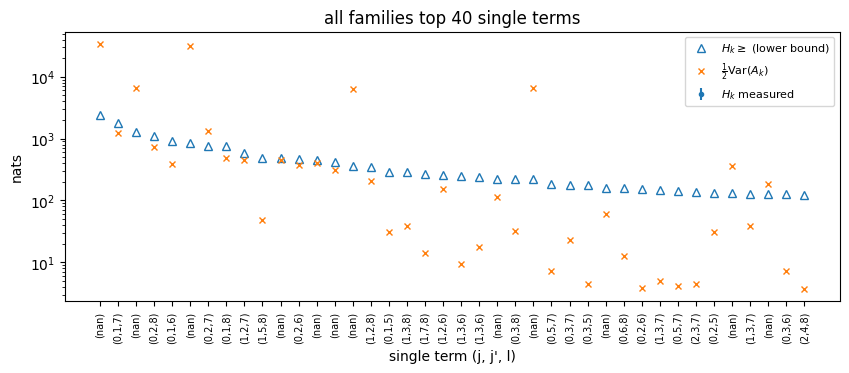

In [3]:
for fam in ('Fourth_Order_Mod2_Real', 'Fourth_Order_Mod2_Imag'):
    if agg.family.str.contains(fam).any():
        P.singles(agg, fam, title=fam); plt.show()
P.singles(agg, '.', title='all families'); plt.show()

## $D_{j,j'}$ (all $l$) vs $|j-j'|$ and $(j,j')$ heatmap
Hypothesis to TEST: decay with $|j-j'|$, possibly dominated by $|j-j'|=1$.

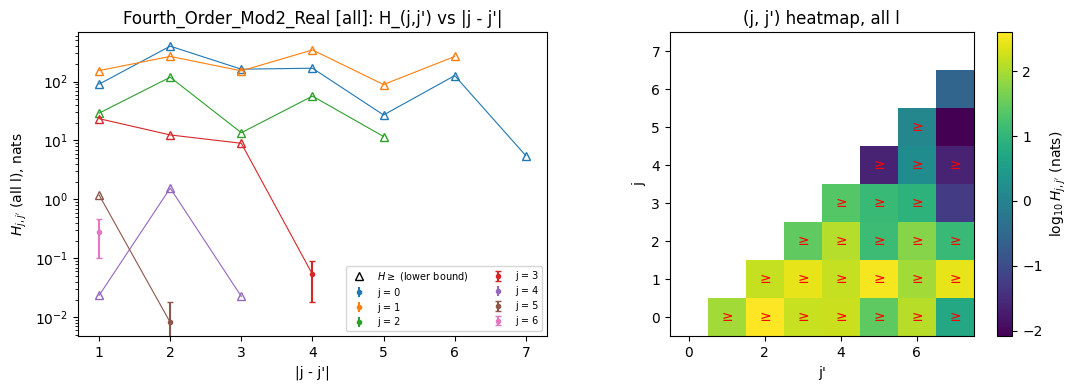

          mean         max  count
dj                               
1    42.497537  153.184542      7
2   132.882997  398.225477      6
3    67.231488  161.830205      5
4   142.024439  343.178291      4
5    42.556901   88.898253      3
6   195.961821  265.949656      2
7     5.535298    5.535298      1


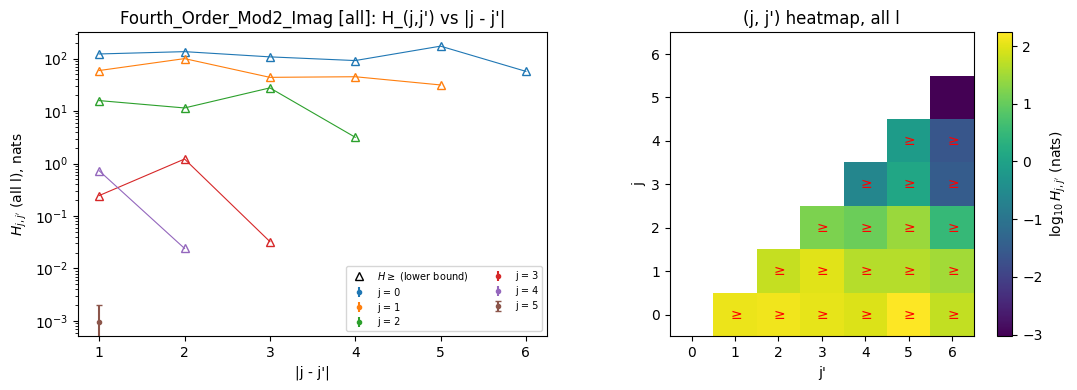

          mean         max  count
dj                               
1    33.112027  122.600538      6
2    49.684592  135.731012      5
3    44.889713  107.921224      4
4    46.691775   91.774212      3
5   102.112496  172.750453      2
6    57.163168   57.163168      1


In [4]:
for fam in ('Fourth_Order_Mod2_Real', 'Fourth_Order_Mod2_Imag'):
    for ang in ('all',):
        if ((agg.kind == 'pair') & agg.family.str.contains(fam) & (agg.label == ang)).any():
            d = P.pairs(agg, fam, title=f'{fam} [{ang}]', angle=ang); plt.show()
            print(d.groupby('dj').H.agg(['mean', 'max', 'count']).to_string())

## Diagnostics: ESS of the weights $e^{A_k}$, $\hat D_k$ vs N for the top contributors

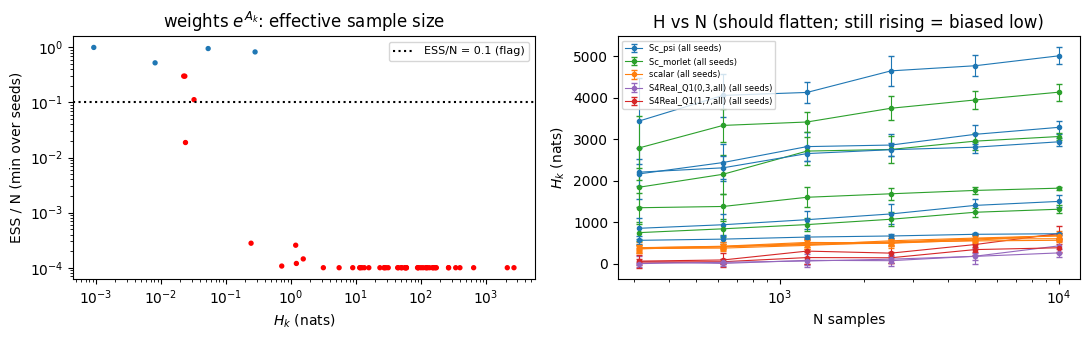

In [5]:
P.diagnostics(agg, DS, Path(os.environ['KL_RESULTS'])); plt.show()

## Summary table (ratio = $D_k / \frac12$Var)

In [6]:
P.summary(agg, kinds=('category', 'family')).round(4)

,name,n_terms,H_k,regime,H_seed_std,H_min,H_max,boot,var2,var2_seed_std,ratio,log10_N_needed,ess,wmax,drift,n_seeds
4,fam:Sc_psi,132,>= 2.7e+03,lower bound,1664.7093,728.8557,5016.6506,123.7526,45511.0087,28297.3646,0.0593,39530.3599,0.0001,1.0,166.8798,5
3,fam:Sc_morlet,60,>= 2.13e+03,lower bound,1505.6917,288.6437,4140.5501,85.5312,43308.8166,28153.0674,0.0492,37617.5601,0.0001,1.0,105.9774,5
0,cat:scalar,192,>= 647,lower bound,55.0817,570.9408,699.7898,59.2553,5233.6105,42.4413,0.1237,4545.8563,0.0001,1.0,72.3967,5
5,fam:S4Imag_Q1,56,>= 59.9,lower bound,52.3669,6.0788,140.3800,20.9483,2.3228,1.4119,25.7902,2.0176,0.0001,1.0,21.9055,5
1,cat:scat4_imag,56,>= 59.9,lower bound,52.3669,6.0788,140.3800,20.9483,2.3228,1.4119,25.7902,2.0176,0.0001,1.0,21.9055,5
2,cat:scat4_real,84,>= 50.3,lower bound,49.3634,18.2732,133.6267,15.4702,11.4907,7.8371,4.3817,9.9807,0.0001,1.0,17.7537,5
6,fam:S4Real_Q1,84,>= 50.3,lower bound,49.3634,18.2732,133.6267,15.4702,11.4907,7.8371,4.3817,9.9807,0.0001,1.0,17.7537,5


In [7]:
P.summary(agg, kinds=('pair',)).head(30).round(4)

,name,n_terms,H_k,regime,H_seed_std,H_min,H_max,boot,var2,var2_seed_std,ratio,log10_N_needed,ess,wmax,drift,n_seeds
361,"pair:S4Real_Q1(0,2,all)",6,>= 398,lower bound,521.6145,0.3464,1193.0919,154.6019,37.9580,32.8561,10.4912,32.9699,0.0001,1.0,170.7094,5
370,"pair:S4Real_Q1(1,5,all)",3,>= 343,lower bound,414.0644,45.2037,1055.4437,89.8114,25.2589,35.3343,13.5864,21.9396,0.0001,1.0,108.9764,5
368,"pair:S4Real_Q1(1,3,all)",5,>= 267,lower bound,210.1169,50.0694,517.7955,65.6539,16.9970,13.5079,15.6914,14.7634,0.0001,1.0,77.1581,5
372,"pair:S4Real_Q1(1,7,all)",1,>= 266,lower bound,301.7148,0.0556,732.6372,68.0609,14.0020,19.9207,18.9937,12.1620,0.0001,1.0,93.5957,5
343,"pair:S4Imag_Q1(0,5,all)",2,>= 173,lower bound,221.3138,17.3792,560.5464,67.6677,4.2870,7.5239,40.2962,3.7237,0.0001,1.0,79.1964,5
363,"pair:S4Real_Q1(0,4,all)",4,>= 168,lower bound,64.7489,75.5504,250.2541,48.3682,9.8308,13.3809,17.1172,8.5389,0.0001,1.0,59.0420,5
362,"pair:S4Real_Q1(0,3,all)",5,>= 162,lower bound,185.4559,0.5230,436.8669,61.0916,15.6042,12.9509,10.3709,13.5536,0.0001,1.0,74.5574,5
367,"pair:S4Real_Q1(1,2,all)",6,>= 153,lower bound,163.7648,29.9050,368.2162,36.9656,13.5128,14.8085,11.3363,11.7370,0.0001,1.0,39.9840,5
369,"pair:S4Real_Q1(1,4,all)",4,>= 152,lower bound,337.7813,0.3586,756.0482,50.0658,18.9370,14.4435,8.0164,16.4485,0.0001,1.0,67.5791,5
340,"pair:S4Imag_Q1(0,2,all)",5,>= 136,lower bound,182.2304,0.0975,456.0379,36.2710,8.8815,7.3317,15.2824,7.7144,0.0001,1.0,33.1363,5
